# 2 · Drug offences over time

I decided to drill down to drug offence as it will show some interesting dynamics. Figures are saved to `notebooks/outputs/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 60)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA = ROOT / 'data' / 'processed'
FIG = ROOT / 'notebooks' / 'outputs'
FIG.mkdir(exist_ok=True)

SURFACE, INK, INK_2, MUTED, GRID, AXIS, NEUTRAL = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#f0efec'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'font.family': 'sans-serif', 'font.sans-serif': ['Helvetica Neue', 'Arial', 'DejaVu Sans'], 'font.size': 10,
    'text.color': INK, 'axes.labelcolor': INK_2, 'axes.edgecolor': AXIS, 'axes.linewidth': 0.8,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.titlepad': 12,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.grid.axis': 'y', 'axes.axisbelow': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
    'xtick.color': AXIS, 'ytick.color': AXIS, 'xtick.labelcolor': INK_2, 'ytick.labelcolor': INK_2,
    'legend.frameon': False, 'figure.dpi': 110,
})
thousands = FuncFormatter(lambda x, _: f'{x:,.0f}')


def save(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=150, bbox_inches='tight')


## 1. Drill down onto drug offences

In Victoria, CSA Table 06  holds only the **C Drug offences** division, split by **offence group** (dealing, trafficking, possession, …) and **CSA drug type**.

In [2]:
# Let's drill down onto one
cat = pd.read_parquet(DATA / 'drug_type_lga.parquet')   # Table 06: C Drug offences only
cat['Descript'] = cat['subgroup'] + ' – ' + cat['drug_type']

# Bin crime by time window: CSA only publishes financial years, so the window is 1 year
cat['Year'] = cat['year']

# Default
district = 'All'

print(f"{cat['offences'].sum():,} drug offences, {cat['Year'].min()}–{cat['Year'].max()}, "
      f"{cat['lga'].nunique()} LGAs, {cat['Descript'].nunique()} descriptions")
cat[['Year', 'lga', 'Descript', 'offences']].head()


323,654 drug offences, 2017–2026, 79 LGAs, 38 descriptions


,Year,lga,Descript,offences
0,2026,Alpine,C21 Cultivate drugs – Cannabis,1
1,2026,Alpine,C23 Possess drug manufacturing equipment or pr...,1
2,2026,Alpine,C32 Drug possession – Cannabis,7
3,2026,Alpine,C32 Drug possession – Cocaine,2
4,2026,Alpine,C32 Drug possession – Ecstasy,1


## 2. Time series: descriptions per year

In [3]:
def timeseries(dat, per):
    """ Descript grouped by year """

    # Group by year and crime description
    cat_per_time = dat.groupby(['Year', 'Descript'])['offences'].sum()
    t = cat_per_time.unstack().fillna(0)

    # Filter by total offences per description
    crime_sum = t.sum(axis=0).sort_values()

    # Large number, so let's slice the data.
    p = np.percentile(crime_sum, per)
    ix = crime_sum[crime_sum >= p]
    t = t[ix.index]
    return t


t_all = timeseries(cat, 0)
print(t_all.shape, '(years × descriptions)')
t_all.T.sort_values(t_all.index[-1], ascending=False).astype(int)   # transposed so the 10 years fit across


(10, 38) (years × descriptions)


Year,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
Descript,,,,,,,,,,
C32 Drug possession – Cannabis,8282,7877,8566,10284,9967,8310,7891,7573,7861,7938
C32 Drug possession – Methylamphetamine,5932,5848,6341,6997,6485,5139,5472,6089,7325,7662
C32 Drug possession – Prescription,2872,3345,3920,4481,5050,4499,4601,4585,4395,5069
C32 Drug possession – Not Recorded,1117,1286,1452,1773,1832,1518,1580,1718,1907,2463
C23 Possess drug manufacturing equipment or precursor – Not Coded,585,401,362,566,990,805,1163,1529,1618,1747
C32 Drug possession – GHB,799,913,663,1435,1659,1027,1376,1421,1640,1609
C12 Drug trafficking – Methylamphetamine,1840,1732,1666,1888,1777,1276,1372,1369,1044,1131
C32 Drug possession – Cocaine,405,495,683,792,772,862,772,827,834,1036
C32 Drug possession – Heroin,906,930,959,1039,906,760,754,713,926,984


## 3. Group the drug categories

38 descriptions are too many to read, so they are compressed into drug groups.

* **METH** joins methylamphetamine and amphetamine.
* **COKE** has no crack split, because CSA does not separate base/rock cocaine.
* **OTHER / UNKNOWN** collects CSA's `Other`, `Not Recorded` and `Not Coded`, so the groups still add up to every drug offence.

In [4]:
# One list of descriptions per drug group, largest group first
weed_features = ['C12 Drug trafficking – Cannabis',
                 'C21 Cultivate drugs – Cannabis',
                 'C31 Drug use – Cannabis',
                 'C32 Drug possession – Cannabis']

meth_features = ['C12 Drug trafficking – Methylamphetamine',
                 'C31 Drug use – Methylamphetamine',
                 'C32 Drug possession – Methylamphetamine',
                 'C12 Drug trafficking – Amphetamine',
                 'C31 Drug use – Amphetamine',
                 'C32 Drug possession – Amphetamine']

prescription_features = ['C12 Drug trafficking – Prescription',
                         'C31 Drug use – Prescription',
                         'C32 Drug possession – Prescription']

ghb_features = ['C12 Drug trafficking – GHB',
                'C31 Drug use – GHB',
                'C32 Drug possession – GHB']

heroin_features = ['C12 Drug trafficking – Heroin',
                   'C31 Drug use – Heroin',
                   'C32 Drug possession – Heroin']

ecstasy_features = ['C12 Drug trafficking – Ecstasy',
                    'C31 Drug use – Ecstasy',
                    'C32 Drug possession – Ecstasy']

coke_features = ['C12 Drug trafficking – Cocaine',
                 'C31 Drug use – Cocaine',
                 'C32 Drug possession – Cocaine']

# CSA drug type 'Other', 'Not Recorded' or 'Not Coded'
other_features = ['C11 Drug dealing – Other',
                  'C12 Drug trafficking – Other',
                  'C23 Possess drug manufacturing equipment or precursor – Other',
                  'C31 Drug use – Other',
                  'C32 Drug possession – Other',
                  'C11 Drug dealing – Not Recorded',
                  'C12 Drug trafficking – Not Recorded',
                  'C31 Drug use – Not Recorded',
                  'C32 Drug possession – Not Recorded',
                  'C21 Cultivate drugs – Not Coded',
                  'C22 Manufacture drugs – Not Coded',
                  'C23 Possess drug manufacturing equipment or precursor – Not Coded',
                  'C99 Other drug offences – Not Coded']

features = {
    'WEED': weed_features,
    'METH': meth_features,
    'PRESCRIPTION': prescription_features,
    'GHB': ghb_features,
    'HEROIN': heroin_features,
    'ECSTASY': ecstasy_features,
    'COKE': coke_features,
    'OTHER / UNKNOWN': other_features,
}
GROUP_COLOURS = dict(zip(features, ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', AXIS]))

# Check: every name is a real description, and every description is in exactly one list
listed = [d for f in features.values() for d in f]
unknown = sorted(set(listed) - set(cat['Descript']))
missing = sorted(set(cat['Descript']) - set(listed))
assert not unknown and not missing and len(listed) == len(set(listed)), f'unknown: {unknown}  missing: {missing}'

pd.DataFrame({'descriptions': {g: len(f) for g, f in features.items()},
              'offences 2017–2026': {g: int(t_all[f].sum().sum()) for g, f in features.items()}})


,descriptions,offences 2017–2026
WEED,4,103182
METH,6,86423
PRESCRIPTION,3,43935
GHB,3,16572
HEROIN,3,12027
ECSTASY,3,11929
COKE,3,10882
OTHER / UNKNOWN,13,38704


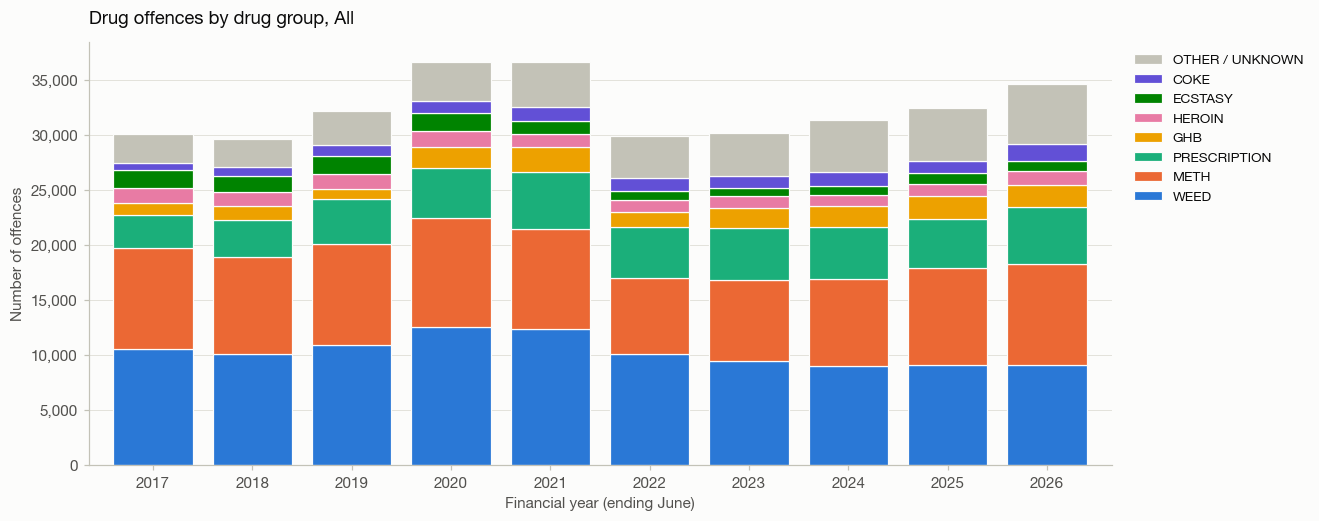

,WEED,METH,PRESCRIPTION,GHB,HEROIN,ECSTASY,COKE,OTHER / UNKNOWN
Year,,,,,,,,
2017,10515,9234,2997,1106,1316,1674,593,2679
2018,10076,8800,3433,1199,1311,1462,766,2611
2019,10934,9189,4039,911,1377,1641,1029,3065
2020,12591,9839,4571,1933,1426,1589,1160,3522
2021,12380,9044,5184,2258,1235,1202,1199,4116
2022,10054,6983,4601,1369,1103,754,1218,3840
2023,9493,7334,4720,1852,1013,741,1092,3906
2024,9017,7935,4720,1903,930,887,1223,4772
2025,9066,8825,4479,2038,1129,989,1143,4737


In [5]:
def drug_analysis(t, district, plot):
    # Sum each group's descriptions; intersection skips descriptions missing from t
    drugs = pd.DataFrame({group: t[t.columns.intersection(f)].sum(axis=1) for group, f in features.items()})
    if plot:
        ax = drugs.plot(kind='bar', stacked=True, figsize=(12, 5), color=[GROUP_COLOURS[g] for g in drugs],
                        width=0.8, edgecolor=SURFACE, linewidth=0.8)
        ax.set_title(f'Drug offences by drug group, {district}')
        ax.set_xlabel('Financial year (ending June)')
        ax.set_ylabel('Number of offences')
        ax.yaxis.set_major_formatter(thousands)
        ax.tick_params(axis='x', rotation=0)
        ax.xaxis.grid(False)   # pandas switches on both grids
        handles, labels = ax.get_legend_handles_labels()
        ax.legend(handles[::-1], labels[::-1], loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=9)
    return drugs


drug_df_all = drug_analysis(t_all, district, True)
save(plt.gcf(), '02_s3_drug_groups')
plt.show()
drug_df_all.astype(int)


## 4. Rescale: share of each drug group per year

The yearly totals go up and down, which makes the drug groups hard to compare between years. Rescaling each year to
100% shows how the mix changes.

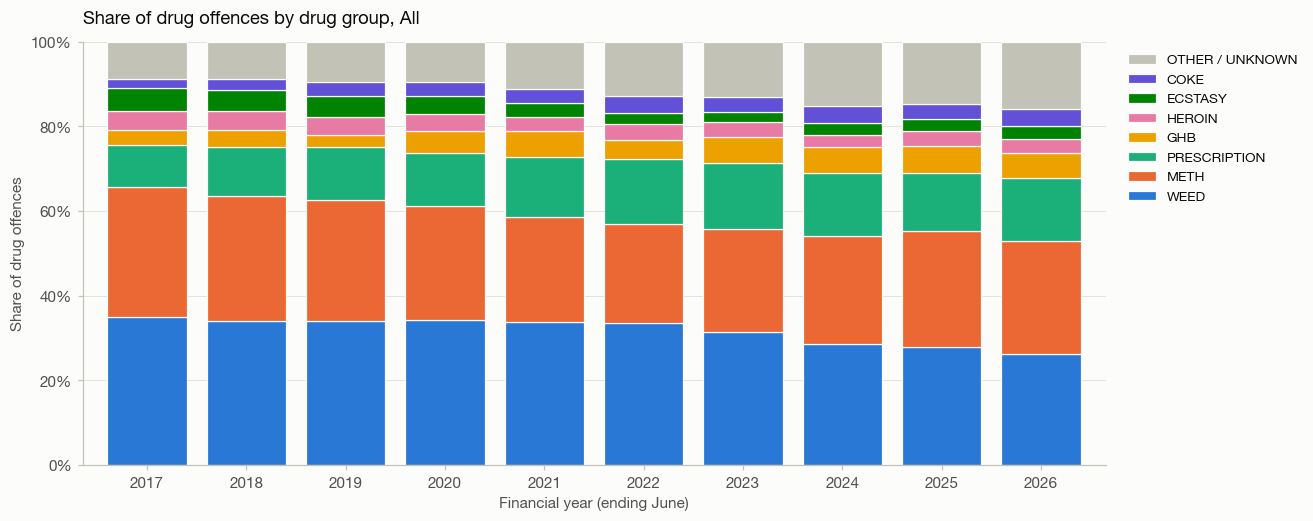

,WEED,METH,PRESCRIPTION,GHB,HEROIN,ECSTASY,COKE,OTHER / UNKNOWN
Year,,,,,,,,
2017,34.9,30.7,10.0,3.7,4.4,5.6,2.0,8.9
2018,34.0,29.7,11.6,4.0,4.4,4.9,2.6,8.8
2019,34.0,28.6,12.5,2.8,4.3,5.1,3.2,9.5
2020,34.4,26.9,12.5,5.3,3.9,4.3,3.2,9.6
2021,33.8,24.7,14.2,6.2,3.4,3.3,3.3,11.2
2022,33.6,23.3,15.4,4.6,3.7,2.5,4.1,12.8
2023,31.5,24.3,15.7,6.1,3.4,2.5,3.6,13.0
2024,28.7,25.3,15.0,6.1,3.0,2.8,3.9,15.2
2025,28.0,27.2,13.8,6.3,3.5,3.1,3.5,14.6


In [6]:
def drug_analysis_rescale(t, district, plot):
    # Same groups as drug_analysis, rescaled so each year sums to 1
    drugs = drug_analysis(t, district, False)
    drugs = drugs.div(drugs.sum(axis=1), axis=0)
    if plot:
        ax = drugs.plot(kind='bar', stacked=True, figsize=(12, 5), color=[GROUP_COLOURS[g] for g in drugs],
                        width=0.8, edgecolor=SURFACE, linewidth=0.8)
        ax.set_title(f'Share of drug offences by drug group, {district}')
        ax.set_xlabel('Financial year (ending June)')
        ax.set_ylabel('Share of drug offences')
        ax.set_ylim(0, 1)
        ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:.0%}'))
        ax.tick_params(axis='x', rotation=0)
        ax.xaxis.grid(False)   # pandas switches on both grids
        handles, labels = ax.get_legend_handles_labels()
        ax.legend(handles[::-1], labels[::-1], loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=9)
    return drugs


drug_df_all_rescale = drug_analysis_rescale(t_all, district, True)
save(plt.gcf(), '02_s4_drug_share')
plt.show()
(drug_df_all_rescale * 100).round(1)   # % of each year's drug offences


## 5. Drug groups by region

Drug offences for each of the 15 regions (6 metropolitan, 9 regional), 2017–2026. Regions differ a lot in population,
so they are compared as **offences per 100,000 residents a year**. The numbers in the cells are these rates.

* **Scaled within each drug:** where is each drug highest?
* **Scaled within each region:** which drugs lead in each region?

In [7]:
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

lga_lookup = pd.read_parquet(DATA / 'lga_lookup.parquet')
lga_population = pd.read_parquet(DATA / 'lga_population.parquet')
region_of = lga_lookup.set_index('lga')['region']
cat['Region'] = cat['lga'].map(region_of)
assert cat['Region'].notna().all() and set(lga_population['year']) == set(cat['Year'])

# Drug totals for each region
stor = []
for d in sorted(cat['Region'].unique()):
    # Specify region and group by time
    t = timeseries(cat[cat['Region'] == d], 0)
    stor.append(drug_analysis(t, d, False).sum(axis=0).rename(d))
drug_dat = pd.concat(stor, axis=1)   # drug groups × regions, offences 2017–2026

# Offences per 100,000 residents a year (population summed over the same years)
region_pop = lga_population.assign(Region=lga_population['lga'].map(region_of)).groupby('Region')['population'].sum()
region_rate = (drug_dat.div(region_pop, axis=1) * 1e5).T   # regions × drug groups
region_rate.round().astype(int)


,WEED,METH,PRESCRIPTION,GHB,HEROIN,ECSTASY,COKE,OTHER / UNKNOWN
Barwon,131,116,67,24,8,17,9,49
Central Highlands,130,107,37,12,5,19,9,37
Eastern Metro,108,96,60,20,10,12,11,46
Gippsland,259,172,64,34,10,19,11,74
Goulburn,251,204,68,31,4,19,16,63
Great South Coast,239,160,61,16,8,24,9,44
Inner Metro,256,281,177,62,93,69,70,164
Inner South-east Metro,79,70,49,15,10,13,17,42
Loddon Campaspe,147,123,44,19,7,16,7,51
Mallee,318,225,75,13,9,29,17,107


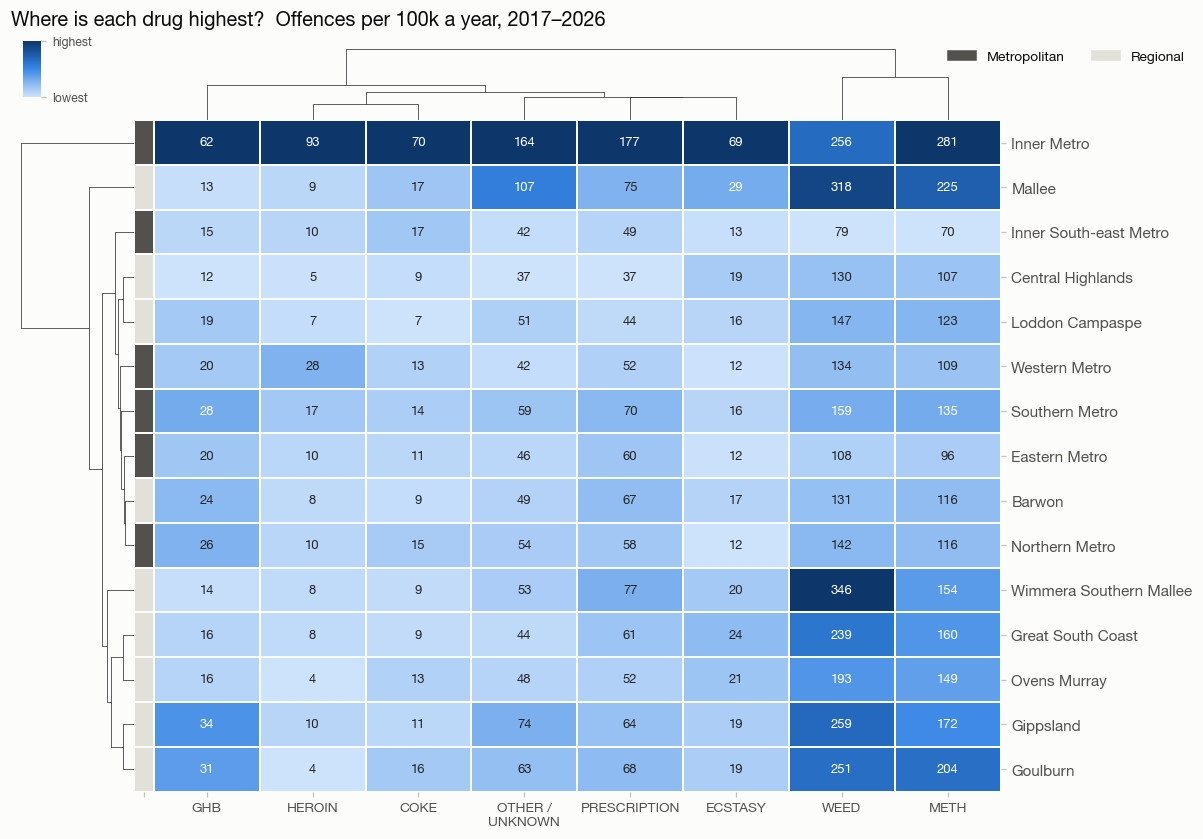

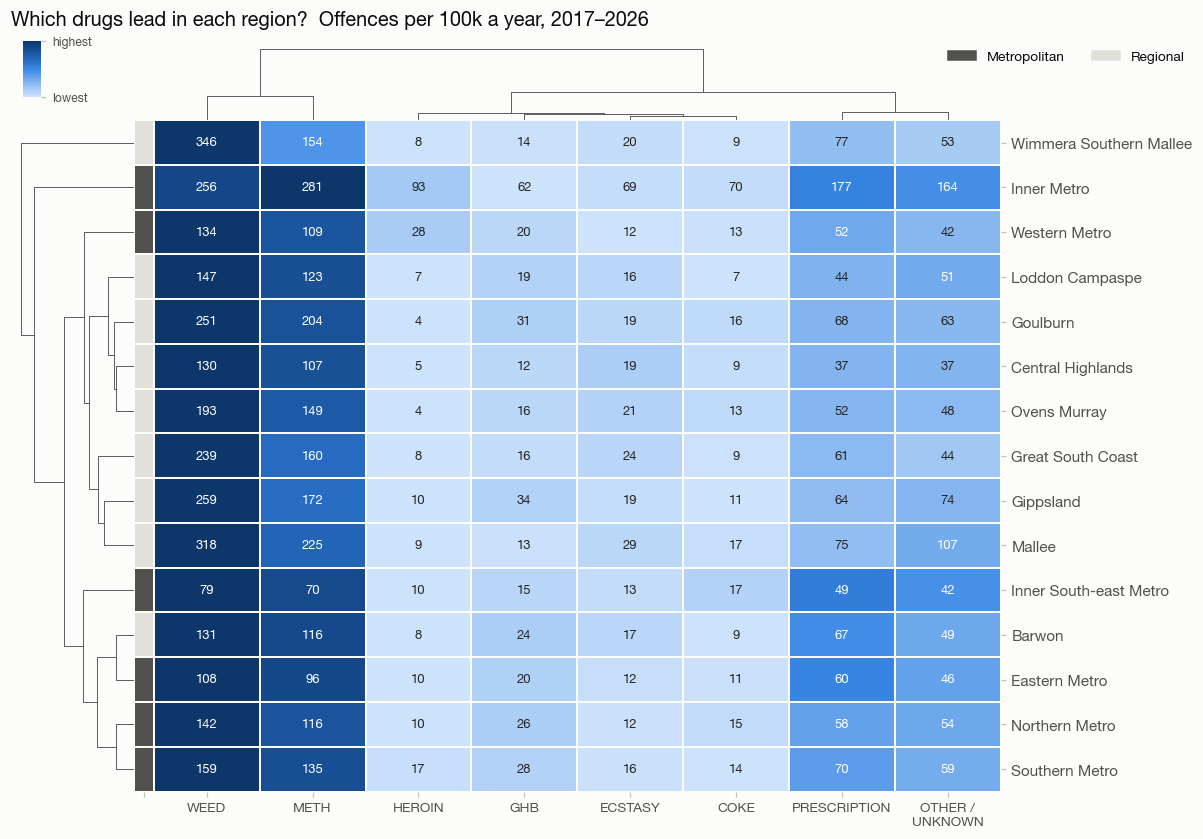

In [8]:
BLUES = LinearSegmentedColormap.from_list('blues', ['#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95', '#0d366b'])
AREA_COLOURS = {'Metropolitan': INK_2, 'Regional': GRID}
area = lga_lookup.groupby('region')['area_type'].first()


def region_clustermap(standard_scale, title, name):
    g = sns.clustermap(region_rate, standard_scale=standard_scale, cmap=BLUES,
                       annot=region_rate.to_numpy(), fmt='.0f', annot_kws={'fontsize': 8.5},
                       linewidths=1, linecolor=SURFACE, figsize=(11, 8.5), dendrogram_ratio=(0.12, 0.1),
                       row_colors=area.map(AREA_COLOURS).rename(''), colors_ratio=0.02,
                       cbar_kws={'ticks': [0, 1]})
    g.ax_cbar.set_position([0.02, g.ax_heatmap.get_position().y1 + 0.025, 0.015, 0.06])   # above the row dendrogram
    g.ax_heatmap.set(xlabel='', ylabel='')
    g.ax_heatmap.set_xticklabels([c.replace(' / ', ' /\n') for c in g.data2d.columns], rotation=0, fontsize=9)
    g.ax_cbar.set_yticklabels(['lowest', 'highest'], fontsize=8)
    g.figure.legend(handles=[Patch(color=c, label=a) for a, c in AREA_COLOURS.items()], loc='upper right',
                    bbox_to_anchor=(0.99, 0.99), ncol=2, fontsize=9)
    g.figure.suptitle(title, x=0.01, y=1.02, ha='left', fontsize=13, fontweight='bold')
    g.savefig(FIG / f'{name}.png', dpi=130, bbox_inches='tight')
    plt.show()


region_clustermap(1, 'Where is each drug highest?  Offences per 100k a year, 2017–2026',
                  '02_s5_cluster_where')
region_clustermap(0, 'Which drugs lead in each region?  Offences per 100k a year, 2017–2026',
                  '02_s5_cluster_mix')


## 6. Drug groups over time

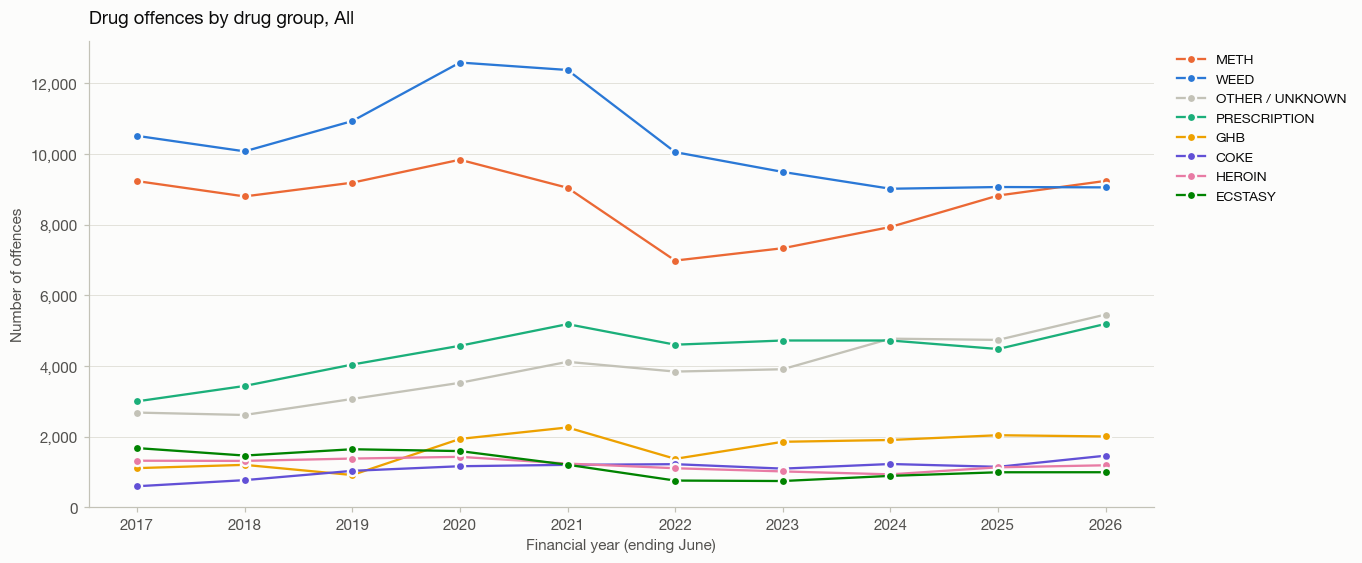

In [9]:
fig, ax = plt.subplots(figsize=(12.5, 5.5))
for d in drug_df_all.iloc[-1].sort_values(ascending=False).index:   # legend in the order of the latest year
    ax.plot(drug_df_all.index, drug_df_all[d], 'o-', color=GROUP_COLOURS[d], ms=6, mew=1.5, mec=SURFACE,
            linewidth=1.5, label=d)
ax.set_title(f'Drug offences by drug group, {district}')
ax.set_xlabel('Financial year (ending June)')
ax.set_ylabel('Number of offences')
ax.set_xticks(drug_df_all.index)
ax.set_ylim(0)
ax.yaxis.set_major_formatter(thousands)
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=9)
save(fig, '02_s6_drug_lines')
plt.show()


## 7. Drug trends by region

Offences per 100,000 residents for each region and year, one panel per region. The grey line is Victoria as a whole.

In [ ]:
# Time series for each region, as offences per 100,000 residents
region_year_pop = (lga_population.assign(Region=lga_population['lga'].map(region_of))
                   .groupby(['Region', 'year'])['population'].sum())
stor_time = []
for d in sorted(cat['Region'].unique()):
    # Specify region and group by time
    t = timeseries(cat[cat['Region'] == d], 0)
    drug_df = drug_analysis(t, d, False).div(region_year_pop[d], axis=0) * 1e5
    drug_df.columns = [f'{c}_{d}' for c in drug_df.columns]
    stor_time.append(drug_df)
drug_dat_time = pd.concat(stor_time, axis=1)   # years × 'GROUP_Region', e.g. 'METH_Inner Metro'
assert drug_dat_time.notna().all().all()

state_rate_time = drug_df_all.div(lga_population.groupby('year')['population'].sum(), axis=0) * 1e5   # Victoria

drug_dat_time.filter(like='METH_').T.round().astype(int)


Year,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
METH_Barwon,133,111,111,143,113,71,93,112,134,134
METH_Central Highlands,138,121,115,113,89,89,96,87,106,124
METH_Eastern Metro,104,96,112,103,116,92,84,84,85,89
METH_Gippsland,173,164,172,217,194,158,148,153,158,185
METH_Goulburn,221,221,217,205,183,131,266,203,169,226
METH_Great South Coast,191,263,218,163,93,87,100,157,172,162
METH_Inner Metro,279,286,284,348,369,276,232,229,255,269
METH_Inner South-east Metro,81,79,75,74,78,50,54,60,75,73
METH_Loddon Campaspe,141,117,130,134,119,78,88,152,130,144
METH_Mallee,168,227,259,272,232,156,234,196,266,242


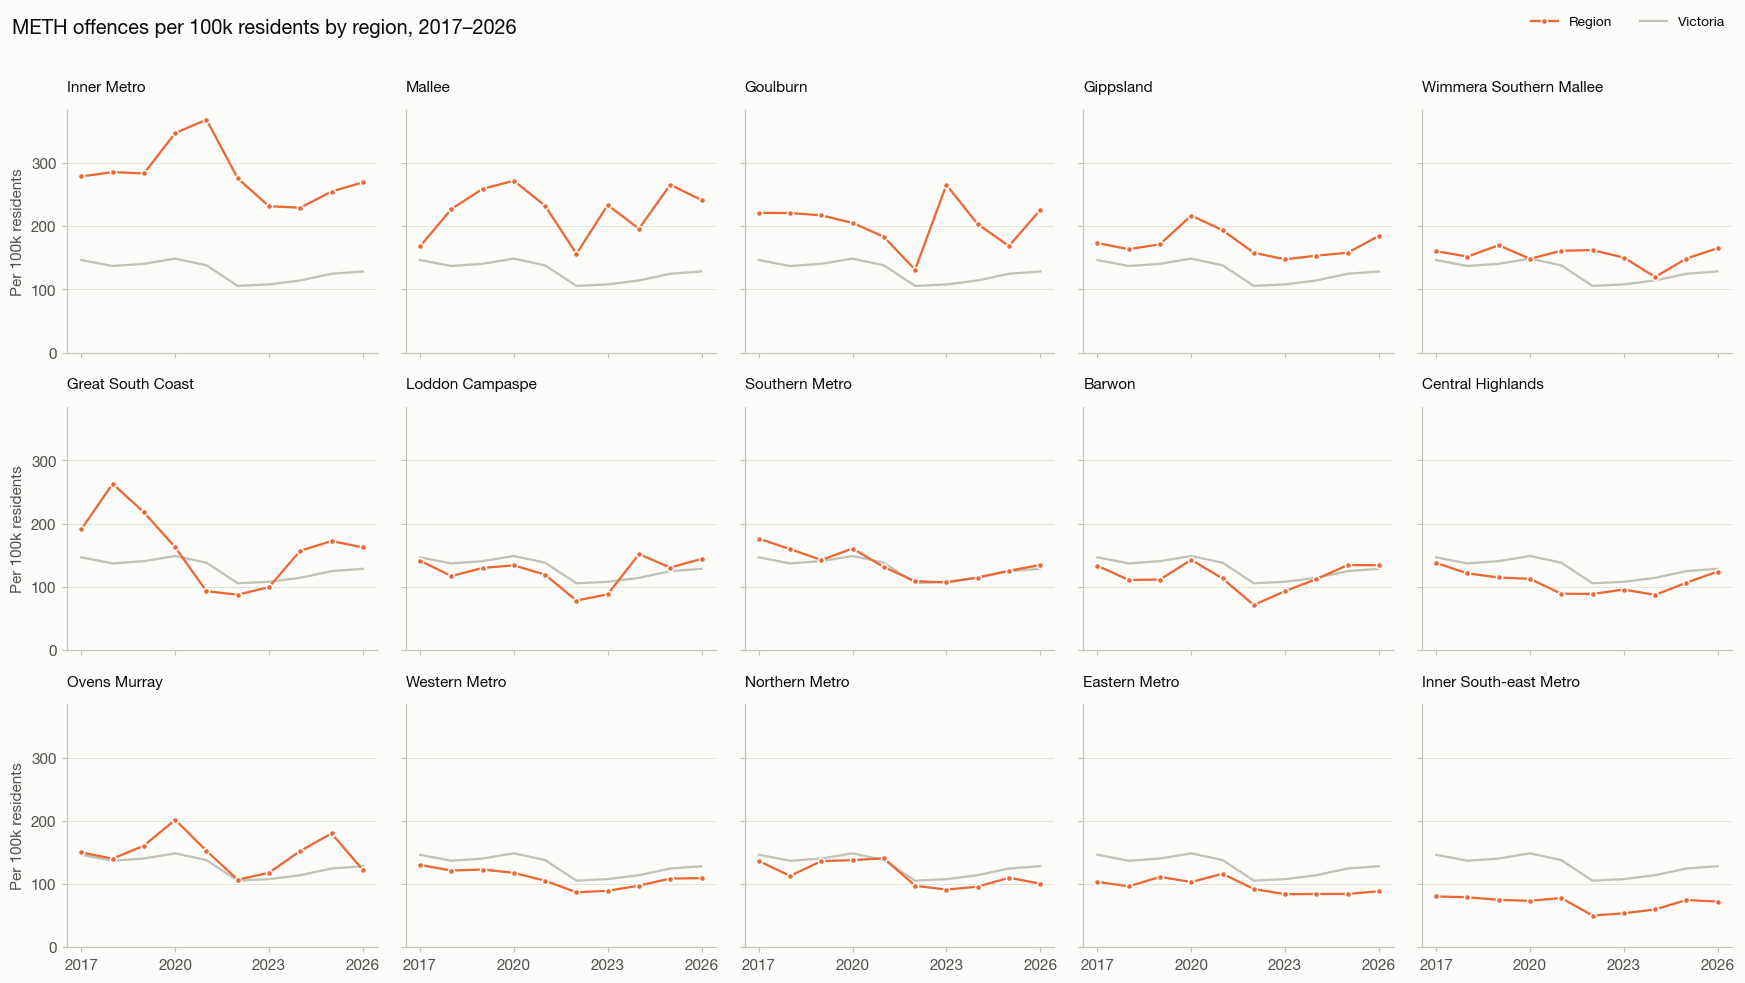

In [ ]:
def region_trends(drug):
    """ One panel per region: rate of one drug group over time, against Victoria """
    cols = drug_dat_time.filter(like=f'{drug}_')
    order = cols.iloc[-1].sort_values(ascending=False).index   # highest rate in the latest year first
    fig, axes = plt.subplots(3, 5, figsize=(16, 9), sharex=True, sharey=True)
    for ax, col in zip(axes.flat, order):
        ax.plot(state_rate_time.index, state_rate_time[drug], color=AXIS, linewidth=1.5, label='Victoria')
        ax.plot(cols.index, cols[col], 'o-', color=GROUP_COLOURS[drug], ms=4, mew=1, mec=SURFACE, linewidth=1.5,
                label='Region')
        ax.set_title(col.split('_', 1)[1], fontsize=10)
        ax.set_xticks([2017, 2020, 2023, 2026])
    ax.set_ylim(0)
    for ax in axes[:, 0]:
        ax.set_ylabel('Per 100k residents')
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles[::-1], labels[::-1], loc='upper right', bbox_to_anchor=(0.99, 0.995), ncol=2, fontsize=9)
    fig.suptitle(f'{drug} offences per 100k residents by region, {cols.index[0]}–{cols.index[-1]}',
                 x=0.01, ha='left', fontsize=13, fontweight='bold')
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    return fig


fig = region_trends('METH')
save(fig, '02_s7_meth_by_region')
plt.show()


## 8. Do regions move together?

Correlation between regions' yearly rates for one drug group: **+1** means two regions rise and fall together, **0** no
relationship, **−1** opposite directions. With only 10 yearly points the correlations are rough: values above about 0.63
(or below −0.63) are unlikely to be chance (p < 0.05).

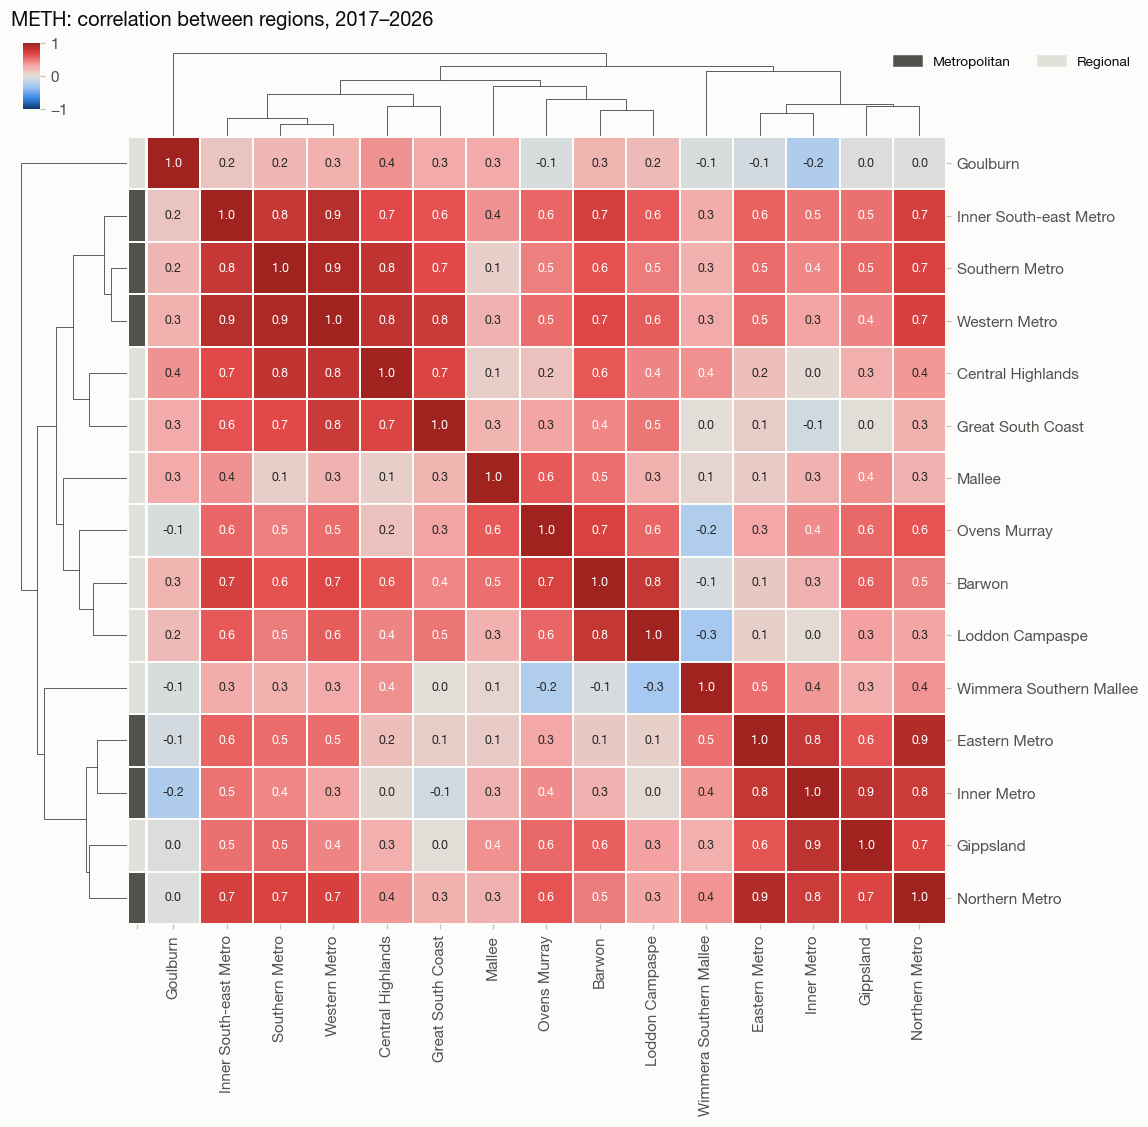

In [ ]:
DIVERGING = LinearSegmentedColormap.from_list('diverging', ['#0d366b', '#3987e5', '#9ec5f4', GRID, '#f4a6a5', '#e34948', '#a1231f'])


def region_correlation(drug):
    """ Correlation between regions' yearly rates for one drug group """
    cols = drug_dat_time.filter(like=f'{drug}_')
    corr = cols.rename(columns=lambda c: c.split('_', 1)[1]).corr()
    g = sns.clustermap(corr, cmap=DIVERGING, vmin=-1, vmax=1, annot=(corr.round(1) + 0).to_numpy(),   # + 0 turns -0.0 into 0.0
                       fmt='.1f', annot_kws={'fontsize': 8},
                       linewidths=1, linecolor=SURFACE, figsize=(10.5, 10), dendrogram_ratio=(0.12, 0.1),
                       row_colors=area.map(AREA_COLOURS).rename(''), colors_ratio=0.02, cbar_kws={'ticks': [-1, 0, 1]})
    g.ax_cbar.set_position([0.02, g.ax_heatmap.get_position().y1 + 0.025, 0.015, 0.06])   # above the row dendrogram
    g.ax_heatmap.set(xlabel='', ylabel='')
    g.figure.legend(handles=[Patch(color=c, label=a) for a, c in AREA_COLOURS.items()], loc='upper right',
                    bbox_to_anchor=(0.99, 0.99), ncol=2, fontsize=9)
    g.figure.suptitle(f'{drug}: correlation between regions, {cols.index[0]}–{cols.index[-1]}',
                      x=0.01, y=1.02, ha='left', fontsize=13, fontweight='bold')
    return g


g = region_correlation('METH')
g.savefig(FIG / '02_s8_meth_region_corr.png', dpi=130, bbox_inches='tight')
plt.show()


In [ ]:
# Every drug group: average correlation over all pairs of regions (high = regions rise and fall together)
pd.Series({drug: drug_dat_time.filter(like=f'{drug}_').corr().where(lambda c: ~np.eye(len(c), dtype=bool)).stack().mean()
           for drug in features}).sort_values(ascending=False).round(2).to_frame('mean correlation between regions')


,mean correlation between regions
ECSTASY,0.64
GHB,0.61
OTHER / UNKNOWN,0.61
WEED,0.61
COKE,0.45
METH,0.40
PRESCRIPTION,0.30
HEROIN,0.24


## 9. Mapping one drug group: before, during and after the lockdown years

Three periods: **2017–2019** (before), **2020–2022** (the COVID-19 lockdown years) and **2023–2026** (after).
Change `drug` in the next cell to map another group, e.g. `'COKE'`.

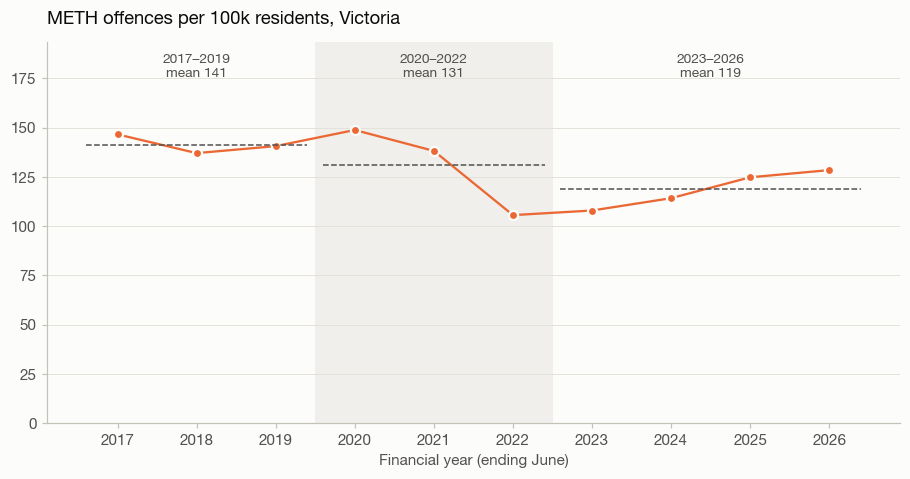

2023–2026 vs 2017–2019: 0.84×   |   2020–2022 vs 2017–2019: 0.93×


In [ ]:
drug = 'METH'
PERIODS = {'2017–2019': [2017, 2018, 2019], '2020–2022': [2020, 2021, 2022], '2023–2026': [2023, 2024, 2025, 2026]}
first, last = list(PERIODS)[0], list(PERIODS)[-1]

# Isolate all records of this drug group
drug_records = cat[cat['Descript'].isin(features[drug])]

# Victoria's rate per year, and the mean of each period
d = state_rate_time[drug]
period_mean = pd.Series({p: d.loc[years].mean() for p, years in PERIODS.items()})

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.axvspan(2019.5, 2022.5, color=NEUTRAL, zorder=0, linewidth=0)
ax.plot(d.index, d, 'o-', color=GROUP_COLOURS[drug], ms=6, mew=1.5, mec=SURFACE, linewidth=1.5)
for p, years in PERIODS.items():
    ax.hlines(period_mean[p], years[0] - 0.4, years[-1] + 0.4, color=INK_2, linestyle='--', linewidth=1)
    ax.text(np.mean(years), 0.97, f'{p}\nmean {period_mean[p]:.0f}', transform=ax.get_xaxis_transform(),
            ha='center', va='top', fontsize=9, color=INK_2)
ax.set_title(f'{drug} offences per 100k residents, Victoria')
ax.set_xlabel('Financial year (ending June)')
ax.set_xticks(d.index)
ax.set_ylim(0, d.max() * 1.3)
save(fig, f'02_s9_{drug.lower()}_periods')
plt.show()

# Fold-difference in mean between periods
print(f'{last} vs {first}: {period_mean[last] / period_mean[first]:.2f}×   |   '
      f'{list(PERIODS)[1]} vs {first}: {period_mean.iloc[1] / period_mean[first]:.2f}×')


In [ ]:
# Average yearly offences per 100,000 residents in each LGA and period
lga_rate = {}
for p, years in PERIODS.items():
    offences = drug_records[drug_records['Year'].isin(years)].groupby('lga')['offences'].sum()
    people = lga_population[lga_population['year'].isin(years)].groupby('lga')['population'].sum()
    lga_rate[p] = offences.reindex(people.index, fill_value=0) / people * 1e5
lga_rate = pd.DataFrame(lga_rate)
lga_rate['change %'] = (lga_rate[last] / lga_rate[first] - 1) * 100

print(f"LGAs with a higher rate in {last} than {first}: {(lga_rate['change %'] > 0).sum()} of {len(lga_rate)}")
lga_rate.sort_values(last, ascending=False).head(10).round()


LGAs with a higher rate in 2023–2026 than 2017–2019: 28 of 79


,2017–2019,2020–2022,2023–2026,change %
lga,,,,
Greater Shepparton,295.0,224.0,360.0,22.0
Melbourne,367.0,453.0,324.0,-11.0
Mildura,264.0,239.0,275.0,4.0
Benalla,170.0,160.0,267.0,58.0
Latrobe,268.0,332.0,265.0,-1.0
Central Goldfields,130.0,122.0,241.0,85.0
Greater Dandenong,264.0,208.0,238.0,-10.0
Wangaratta,226.0,294.0,230.0,2.0
Glenelg,171.0,150.0,223.0,31.0


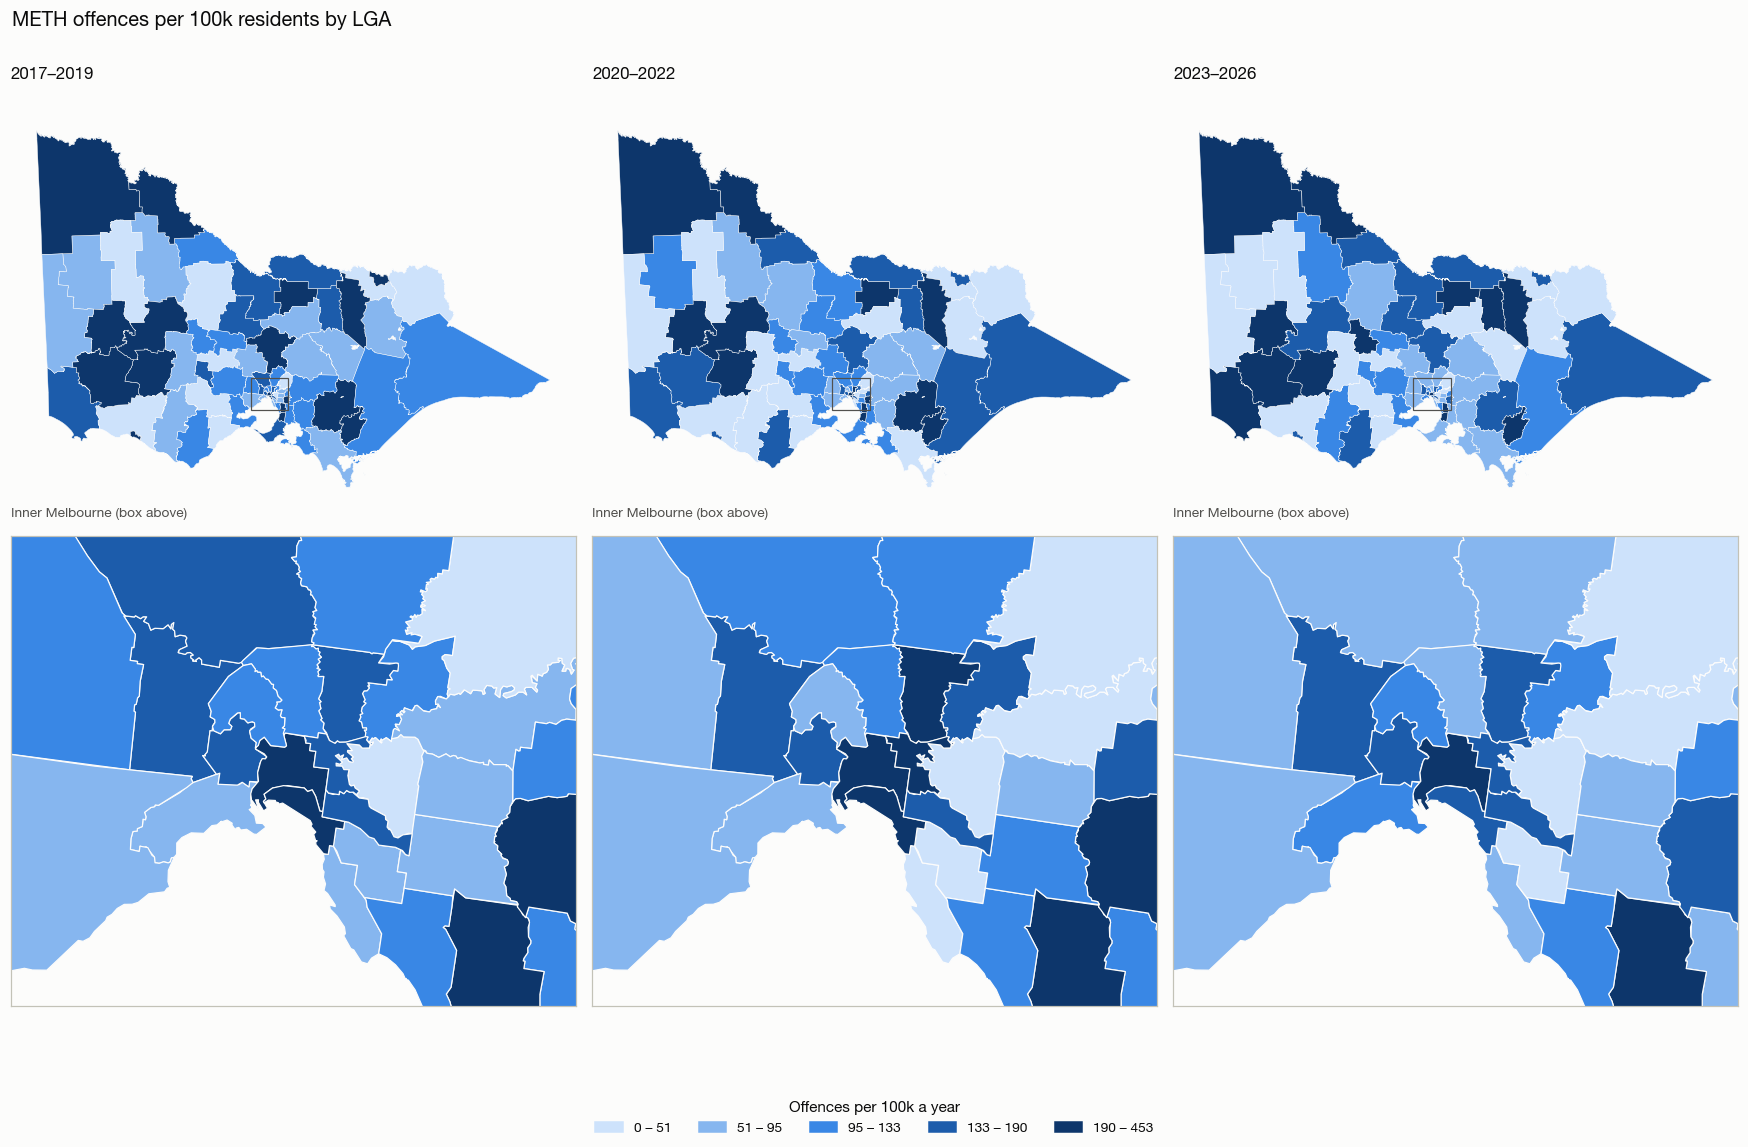

In [ ]:
import geopandas as gpd
from matplotlib.patches import Rectangle

lga_geo = gpd.read_file(DATA / 'lga_boundaries.gpkg').to_crs(7899).set_index('lga')   # GDA2020 / Vicgrid, metres
lga_geo['geometry'] = lga_geo.simplify(100)   # lighter shapes for drawing
rates = lga_rate.loc[lga_geo.index]
cbd = lga_geo.loc['Melbourne'].geometry.representative_point()
zoom = (cbd.x - 30_000, cbd.y - 25_000, cbd.x + 30_000, cbd.y + 25_000)   # inner Melbourne: 30 km around the CBD


def draw(ax, colours, title, metro=False):
    lga_geo.plot(ax=ax, color=colours, edgecolor=SURFACE, linewidth=0.8 if metro else 0.3)
    if metro:
        ax.set(xlim=(zoom[0], zoom[2]), ylim=(zoom[1], zoom[3]), xticks=[], yticks=[], xlabel='', ylabel='')
        for spine in ax.spines.values():
            spine.set(visible=True, color=AXIS)
    else:
        ax.add_patch(Rectangle(zoom[:2], zoom[2] - zoom[0], zoom[3] - zoom[1], fill=False, edgecolor=INK_2, linewidth=0.8))
        ax.set_axis_off()
    ax.set_title(title, fontsize=9 if metro else 11, fontweight='normal' if metro else 'bold',
                 color=INK_2 if metro else INK)


STEPS = ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b']   # sequential blue, light = low
edges = np.quantile(rates[list(PERIODS)].to_numpy(), np.linspace(0, 1, 6))   # one set of classes for every period

fig, axes = plt.subplots(2, 3, figsize=(16, 10.5), gridspec_kw={'height_ratios': [1, 1.25]})
for col, p in enumerate(PERIODS):
    colours = [STEPS[c] for c in pd.cut(rates[p], edges, labels=False, include_lowest=True)]
    draw(axes[0, col], colours, p)
    draw(axes[1, col], colours, 'Inner Melbourne (box above)', metro=True)
fig.legend(handles=[Patch(color=c, label=f'{edges[i]:,.0f} – {edges[i + 1]:,.0f}') for i, c in enumerate(STEPS)],
           title='Offences per 100k a year', loc='lower center', ncol=5, fontsize=9)
fig.suptitle(f'{drug} offences per 100k residents by LGA', x=0.01, ha='left', fontsize=13, fontweight='bold')
fig.tight_layout(rect=(0, 0.06, 1, 0.97))
save(fig, f'02_s9_{drug.lower()}_maps')
plt.show()


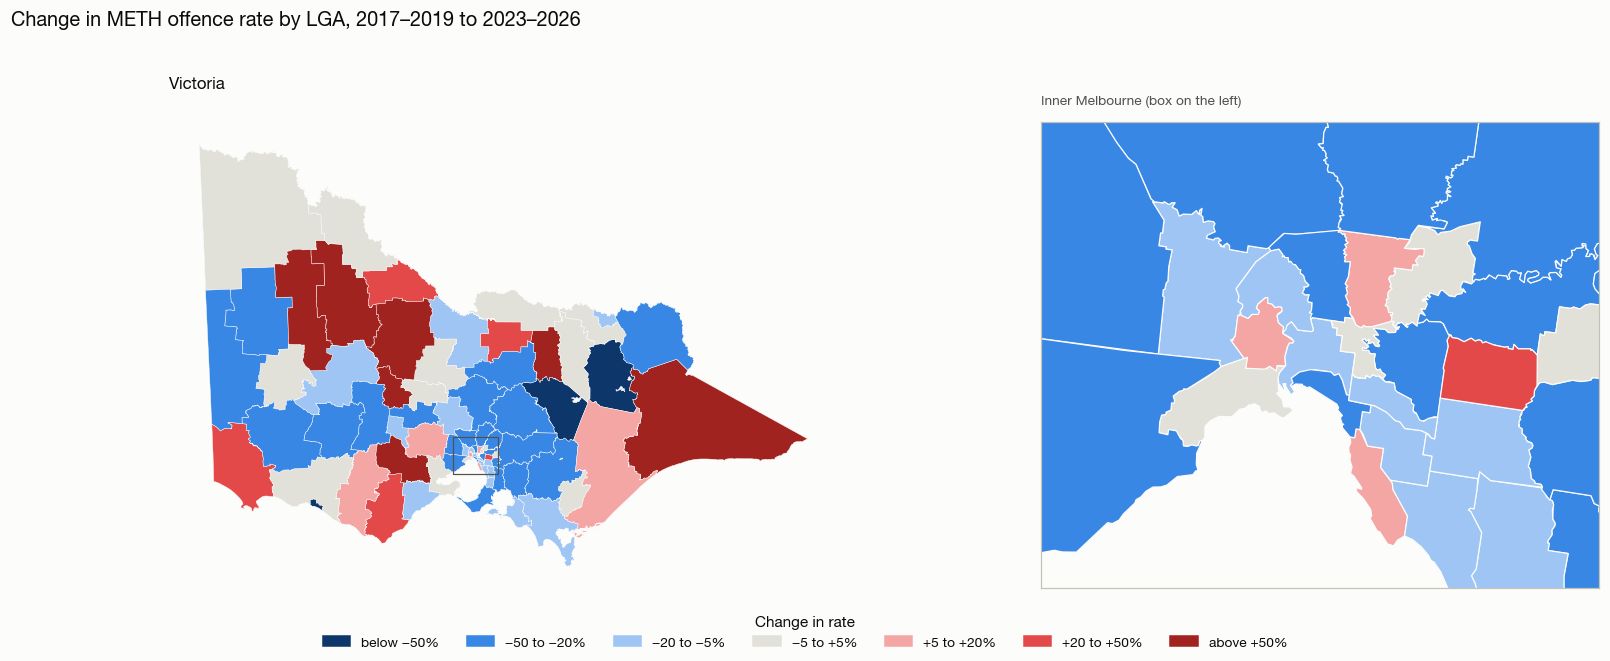

In [ ]:
CHANGE_STEPS = ['#0d366b', '#3987e5', '#9ec5f4', GRID, '#f4a6a5', '#e34948', '#a1231f']   # blue = fall, red = rise
CHANGE_EDGES = [-np.inf, -50, -20, -5, 5, 20, 50, np.inf]
CHANGE_LABELS = ['below −50%', '−50 to −20%', '−20 to −5%', '−5 to +5%', '+5 to +20%', '+20 to +50%', 'above +50%']

colours = [CHANGE_STEPS[c] for c in pd.cut(rates['change %'], CHANGE_EDGES, labels=False)]
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1.6, 1]})
draw(axes[0], colours, 'Victoria')
draw(axes[1], colours, 'Inner Melbourne (box on the left)', metro=True)
fig.legend(handles=[Patch(color=c, label=l) for c, l in zip(CHANGE_STEPS, CHANGE_LABELS)],
           title='Change in rate', loc='lower center', ncol=7, fontsize=9)
fig.suptitle(f'Change in {drug} offence rate by LGA, {first} to {last}', x=0.01, ha='left', fontsize=13, fontweight='bold')
fig.tight_layout(rect=(0, 0.08, 1, 0.95))
save(fig, f'02_s9_{drug.lower()}_change')
plt.show()
